# Week 7: a differentiable ClimateBench emulator

The emulator is in [`emulator.py`](../emulator.py): pattern scaling driven by a lagged linear model of global-mean
warming, with SO2 and BC entering as their first EOF. It takes the raw ClimateBench inputs from 1850 (historical first
for an SSP) and returns tas `(year, lat, lon)`. The choices behind it are in NOTES.md (2026-11-12).

Run with the **Python (jcm)** kernel from the `notebooks/` folder. Everything runs on a laptop CPU in under a minute.

In [1]:
import os
import sys

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

REPO = os.path.abspath("..")
assert os.path.exists(f"{REPO}/emulator.py"), "run from the notebooks/ folder"
sys.path.insert(0, REPO)
import emulator as em
from metrics import nrmse

FIGS = f"{REPO}/figures"
YEARS = np.arange(1850, 2101)
GTC_TO_GTCO2 = 44.01 / 12.011
IPCC_TCRE, IPCC_LIKELY = 0.45, (0.27, 0.63)          # K per 1000 GtCO2 (AR6)
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GRAY = "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "lines.linewidth": 2})

## Task 1: the emulator

Fit on the six training experiments, then score ssp245 tas with the ClimateBench metrics. The target is within about 20%
of our best Week 3 emulator (Gaussian process, tas Total 0.299), so 0.359 or lower.

In [2]:
params = em.fit()
emulate = em.make_emulator(params)
co2, ch4, so2, bc = em.scenario_inputs("ssp245")
w = em.area_weights()                                    # (lat, lon), sums to 1

truth = em.load_tas("ssp245")
pred = xr.DataArray(np.asarray(emulate(co2, ch4, so2, bc))[-86:], dims=truth.dims, coords=truth.coords)
score = nrmse(truth, pred)
print({k: round(v, 3) for k, v in score.items()}, f"-> {score['Total'] / 0.299 - 1:+.0%} vs the GP")
print("core [c0, CO2, CH4, SO2 EOF1, BC EOF1]:", np.round(np.asarray(params["core"]), 3))

{'Spatial': 0.083, 'Global': 0.052, 'Total': 0.345} -> +15% vs the GP
core [c0, CO2, CH4, SO2 EOF1, BC EOF1]: [ 0.073  0.765  0.284 -0.143 -0.077]


## Task 2: the derivative of late-century warming with respect to CO2

$J$ is the area-weighted global-mean tas over 2081–2100 under ssp245. `jax.grad` gives $\partial J / \partial C(t)$ for
the cumulative CO2 input $C$ in every year from 1850 to 2100.

One extra unit emitted in year $t$ raises $C$ in every year from $t$ onwards, so the effect of an emission is the
reverse cumulative sum of the gradient:

$$\frac{\partial J}{\partial E(t)} = \sum_{t' \ge t} \frac{\partial J}{\partial C(t')}$$

In [3]:
def J(co2):
    return (emulate(co2, ch4, so2, bc)[-20:] * w).sum(axis=(1, 2)).mean()


dJ_dC = jax.grad(J)(co2)
dJ_dE = jnp.cumsum(dJ_dC[::-1])[::-1]

print(f"J = {float(J(co2)):.3f} K (years {YEARS[-20]}-{YEARS[-1]})")
for y in [1850, 1950, 2030, 2080, 2081, 2090, 2100]:
    print(f"{y}: dJ/dC = {float(dJ_dC[y - 1850]):.2e}   dJ/dE = {1000 * float(dJ_dE[y - 1850]):.3f} K per 1000 GtCO2")

J = 2.009 K (years 2081-2100)
1850: dJ/dC = 1.45e-105   dJ/dE = 0.386 K per 1000 GtCO2
1950: dJ/dC = 2.47e-62   dJ/dE = 0.386 K per 1000 GtCO2
2030: dJ/dC = 1.37e-27   dJ/dE = 0.386 K per 1000 GtCO2
2080: dJ/dC = 7.10e-06   dJ/dE = 0.382 K per 1000 GtCO2
2081: dJ/dC = 1.93e-05   dJ/dE = 0.375 K per 1000 GtCO2
2090: dJ/dC = 1.93e-05   dJ/dE = 0.201 K per 1000 GtCO2
2100: dJ/dC = 1.22e-05   dJ/dE = 0.012 K per 1000 GtCO2


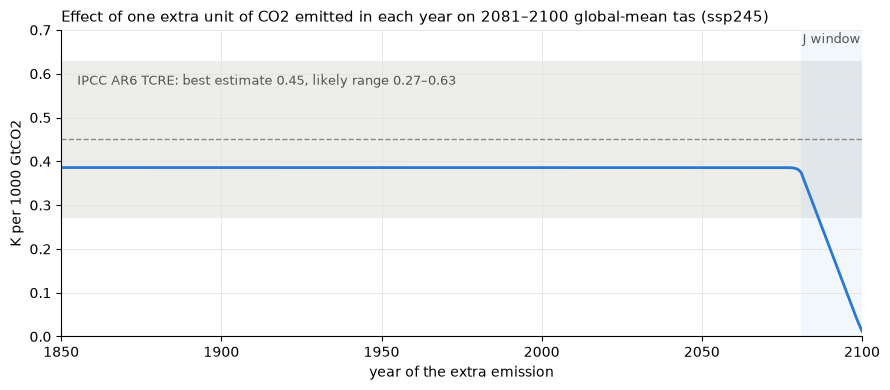

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.axhspan(*IPCC_LIKELY, color=GRAY, alpha=0.15, lw=0)
ax.axhline(IPCC_TCRE, color=GRAY, lw=1, ls="--")
ax.text(1855, IPCC_LIKELY[1] - 0.03, "IPCC AR6 TCRE: best estimate 0.45, likely range 0.27–0.63",
        color="#55554f", fontsize=9, va="top")
ax.axvspan(2081, 2100, color=BLUE, alpha=0.06, lw=0)
ax.text(2090.5, 0.67, "J window", ha="center", color="#55554f", fontsize=9)
ax.plot(YEARS, 1000 * np.asarray(dJ_dE), color=BLUE)
ax.set_xlim(1850, 2100)
ax.set_ylim(0, 0.7)
ax.set_xlabel("year of the extra emission")
ax.set_ylabel("K per 1000 GtCO2")
ax.set_title("Effect of one extra unit of CO2 emitted in each year on 2081–2100 global-mean tas (ssp245)",
             loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(f"{FIGS}/week7_task2_dJdE.png", dpi=150, bbox_inches="tight")

The curve is flat until about 2080 and falls to near zero by 2100. An emission before 2081 raises the cumulative total
in all 20 years of the window, and the emulator's lag is only 1 year, so the timing of the emission does not matter.
An emission inside the window counts only in the years after it. The flat part is the emulator's TCRE: warming per
unit of cumulative emissions, independent of when they were emitted.

### Units of the CO2 input

The input files have no `units` attribute. The ClimateBench paper gives cumulative CO2 emissions in GtCO2. The yearly
increase in 2014 should then equal the fossil CO2 emissions of 2014, about 35.5 GtCO2 (Global Carbon Project).

In [5]:
hist = xr.open_dataset(f"{em.DATA}/inputs_historical.nc").CO2
print(f"cumulative CO2 in 2014: {float(hist.sel(time=2014)):.0f}; increase 2013 -> 2014: "
      f"{float(hist.sel(time=2014) - hist.sel(time=2013)):.1f}")

tcre = 1000 * float(dJ_dE[2030 - 1850])
b_global = float((params["pattern"][1].reshape(em.N_LAT, em.N_LON) * w).sum())
analytic = 1000 * float(params["core"][1] / params["const"]["scale"][0]) * b_global
print(f"emulator TCRE (flat part, 2030): {tcre:.3f} K per 1000 GtCO2")
print(f"closed form c_CO2 / scale_CO2 x global mean of the pattern slope: {analytic:.3f}")

cumulative CO2 in 2014: 1500; increase 2013 -> 2014: 35.6


emulator TCRE (flat part, 2030): 0.386 K per 1000 GtCO2
closed form c_CO2 / scale_CO2 x global mean of the pattern slope: 0.386


The 2014 increase is 35.6, so the input is cumulative **fossil** CO2 in **GtCO2** (land-use emissions are not
included). The emulator's TCRE is **0.386 K per 1000 GtCO2**, inside the IPCC likely range and below its best
estimate. Because the emulator is linear in CO2 with a 1-year lag, the gradient equals the closed form exactly.

### Finite-difference check

Add $\pm\delta$ to the cumulative CO2 from 2030 onwards (one extra emission of $\delta$ in 2030) and take the central
difference.

In [6]:
i = 2030 - 1850
for delta in [1.0, 10.0, 100.0]:
    step = jnp.where(jnp.arange(len(co2)) >= i, delta, 0.0)
    fd = (J(co2 + step) - J(co2 - step)) / (2 * delta)
    print(f"delta = {delta:5.0f} GtCO2: FD = {float(fd):.10e}   grad = {float(dJ_dE[i]):.10e}   "
          f"relative difference {abs(float(fd / dJ_dE[i]) - 1):.0e}")

delta =     1 GtCO2: FD = 3.8575663840e-04   grad = 3.8575663840e-04   relative difference 2e-13
delta =    10 GtCO2: FD = 3.8575663840e-04   grad = 3.8575663840e-04   relative difference 5e-14
delta =   100 GtCO2: FD = 3.8575663840e-04   grad = 3.8575663840e-04   relative difference 8e-15


They agree to about 1e-13 for every step size. The emulator is linear in CO2 and runs in float64, so there is neither
truncation error (no curvature) nor a switch for the finite difference to cross.

### Is 0.386 NorESM2's TCRE?

`1pctCO2` is the standard experiment for TCRE (CO2 only, rising 1% per year), and it is not in the training data. Its
CO2 input is in **GtC**, not GtCO2: at doubling (year 70) it reads 1436, and the atmosphere alone needs about 607 GtC
(285 ppm × 2.13 GtC/ppm) to double, which 1436 GtCO2 (392 GtC) cannot give. The first-year increase, 13 per year, also
fits GtC (about 6 GtC stays in the air with an airborne fraction near one half). The plot converts it to GtCO2.

NorESM2 1pctCO2, years 61-80: 1.50 K at 5331 GtCO2 -> TCRE 0.28 K per 1000 GtCO2
emulator / NorESM2 1pctCO2: 1.37


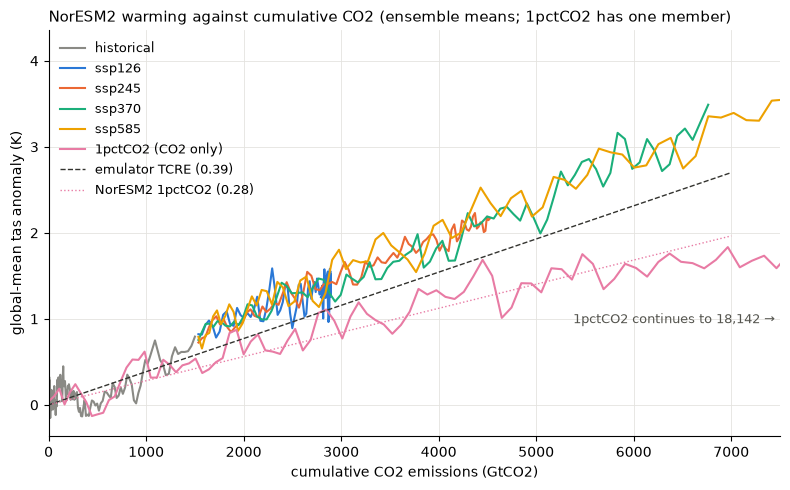

In [7]:
def gmt(da):
    return (da.values.reshape(len(da.time), em.N_LAT, em.N_LON) * np.asarray(w)).sum(axis=(1, 2))


pct_in = xr.open_dataset(f"{em.DATA}/inputs_1pctCO2.nc")
pct_T = gmt(xr.open_dataset(f"{em.DATA}/outputs_1pctCO2.nc").tas.mean("member"))
pct_C = pct_in.CO2.values * GTC_TO_GTCO2
tcre_noresm = 1000 * pct_T[60:80].mean() / pct_C[60:80].mean()
print(f"NorESM2 1pctCO2, years 61-80: {pct_T[60:80].mean():.2f} K at {pct_C[60:80].mean():.0f} GtCO2 "
      f"-> TCRE {tcre_noresm:.2f} K per 1000 GtCO2")
print(f"emulator / NorESM2 1pctCO2: {tcre / tcre_noresm:.2f}")

hist_T = gmt(em.load_tas("historical"))
curves = {"historical": (hist.values, hist_T, GRAY)}
for exp, color in [("ssp126", BLUE), ("ssp245", ORANGE), ("ssp370", AQUA), ("ssp585", YELLOW)]:
    c = np.asarray(em.scenario_inputs(exp)[0])[-86:]
    curves[exp] = (c, gmt(em.load_tas(exp)), color)
curves["1pctCO2 (CO2 only)"] = (pct_C, pct_T, MAGENTA)

fig, ax = plt.subplots(figsize=(8, 5))
for name, (c, T, color) in curves.items():
    ax.plot(c, T, color=color, lw=1.5, label=name)
grid = np.linspace(0, 7000, 2)
ax.plot(grid, tcre / 1000 * grid, color="#33332f", lw=1, ls="--", label=f"emulator TCRE ({tcre:.2f})")
ax.plot(grid, tcre_noresm / 1000 * grid, color=MAGENTA, lw=1, ls=":", label=f"NorESM2 1pctCO2 ({tcre_noresm:.2f})")
ax.set_xlim(0, 7500)
ax.text(7450, 0.95, f"1pctCO2 continues to {pct_C[-1]:,.0f} →", ha="right", color="#55554f", fontsize=9)
ax.set_xlabel("cumulative CO2 emissions (GtCO2)")
ax.set_ylabel("global-mean tas anomaly (K)")
ax.set_title("NorESM2 warming against cumulative CO2 (ensemble means; 1pctCO2 has one member)", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig(f"{FIGS}/week7_task2_tcre.png", dpi=150, bbox_inches="tight")

## Notes (Task 2, and Question 1)

- **TCRE.** The emulator's TCRE is 0.386 K per 1000 GtCO2, inside the IPCC likely range (0.27–0.63) and below the best
  estimate (0.45).
- **It is not NorESM2's CO2-only TCRE.** From 1pctCO2, NorESM2's TCRE is about 0.28, so the emulator is about 37% higher.
  The likely reason: the historical and SSP runs also have N2O and halocarbons, which are not ClimateBench inputs, and
  CH4 rises together with CO2 in most scenarios. The regression gives their warming to the CO2 coefficient. So the
  emulator's "TCRE" is an effective value for all greenhouse gases that rise with CO2. The SSP curves in the second
  figure sit above the 1pctCO2 curve for the same reason. They also sit above the emulator's TCRE line, because the
  emulator adds a separate CH4 term (and subtracts an aerosol term) on top of the CO2 term.
- **Caveats.** 1pctCO2 has one member. Its unit (GtC) is inferred from physics, not from documentation, and we do not
  know how ClimateBench derived its cumulative emissions, so the 0.28 is less certain than the emulator's 0.386. The
  emulator is linear, so it cannot show the small curvature of the real TCRE.
- **Timing.** In this emulator the timing of a CO2 emission before 2081 does not matter for late-century warming, by
  construction (the lag is 1 year). That is close to the physical result for CO2, but it is a property of the model,
  not something the gradient discovered.